# 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

### Import database / data

In [2]:
import os
print(os.getcwd())

C:\Users\Admin\CHURN


- `OS` provides functions for interacting with the operating system.
- `os.getcwd()` returns the current working directory.

In [3]:
import os

# The 'r' prefix creates a raw string so Windows backslashes don't cause errors
folder = r"C:\Users\Admin\Downloads"

# os.walk(folder) searches through the folder and its subfolders
for root, folders, files in os.walk(folder):
    for file in files:
# Looks for the exact filename
        if file == "customer_churn_data_raw.xlsx":
# os.path.join(root, file) combines the folder and filename into a full path
            full_path = os.path.join(root, file)
            print(f"File found: {full_path}")

File found: C:\Users\Admin\Downloads\customer_churn_data_raw.xlsx


### Reading the Excel workbook

In [4]:
excel_file = r'C:\Users\Admin\Downloads\customer_churn_data_raw.xlsx'

In [5]:
customer = pd.read_excel(excel_file, sheet_name="db_customer")
subscription = pd.read_excel(excel_file, sheet_name="db_subscription")
support = pd.read_excel(excel_file, sheet_name="db_support")

### Creating a SQLite database

In [6]:
conn = sqlite3.connect('customer_churn.db')

`SQLite` is a lightweight relational database and stores structured information in tables and supports SQL queries.

- `sqlite3.connect()` opens a connection to a database.
- If the database file doesn't exist, SQLite normally creates it.
- `conn` stores the connection object so Python can communicate with the database.

### Saving Excel sheets as SQL tables

In [7]:
customer.to_sql("db_customer", conn, if_exists="replace", index=False)
subscription.to_sql("db_subscription", conn, if_exists="replace", index=False)
support.to_sql("db_support", conn, if_exists="replace", index=False)

9

- `to_sql()` writes a pandas DataFrame directly into an SQLite database table.
- `"db_customer"` is the destination table name inside the database.
- conn is the active database connection object.
- `if_exists = "replace"` automatically drops and replaces the table if a table with the same name already exists
-  `index = False` prevents pandas from writing its index row numbers into the database as a separate column.

In [8]:
# 5. Close the database connection

conn.close()
print("Database created successfully!")

Database created successfully!


### Storing each table to a separate df


In [9]:
# Connect to database
conn = sqlite3.connect("customer_churn.db")

In [10]:
# Read each table into a DataFrame
df_db_customer = pd.read_sql("SELECT * FROM db_customer", conn)

df_db_subscription = pd.read_sql("SELECT * FROM db_subscription", conn)

df_db_support = pd.read_sql("SELECT * FROM db_support", conn)

In [11]:
# Close connection
conn.close()
print("All tables loaded successfully!")

All tables loaded successfully!


### Print table names and column names

In [12]:
conn = sqlite3.connect('customer_churn.db')

In [13]:
print("db_customer:", df_db_customer.columns.tolist())

db_customer: ['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']


In [14]:
print("db_subscription:", df_db_subscription.columns.tolist())

db_subscription: ['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']


In [15]:
print("db_support:", df_db_support.columns.tolist())

db_support: ['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [16]:
conn.close()

- `.columns` returns the column labels.
- `.tolist()` converts them into a normal Python list.
- print() displays them.

# 2. Data cleaning

### Customer Table

In [17]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [18]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


#### a. Rename Column

In [19]:
df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace = True)

- `rename()` → changes a column name.
- columns → specifies which column to rename.
- `inplace = True` → saves the change directly in the existing DataFrame.

#### b. Drop Unnecessary Columns 

In [20]:
df_db_customer.drop(columns=['interests', 'pincode'], inplace=True) 

#### c. Change DataType 

In [21]:
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

- `pd.to_datetime()` → converts the column values into dates.

#### d. Standardize gender labels

In [22]:
print(df_db_customer['gender'].unique())

['Male' 'Female' 'Women' 'Men']


In [23]:
df_db_customer['gender'] = df_db_customer['gender'].replace({
    'Women': 'Female',
    'Men': 'Male'
})

In [24]:
print(df_db_customer['gender'].unique())

['Male' 'Female']


#### e. Fix missing values|

In [25]:
df_db_customer['country'].isnull()

0     False
1     False
2     False
3     False
4     False
5      True
6     False
7     False
8      True
9     False
10    False
11    False
12     True
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
Name: country, dtype: bool

- `df_db_customer['country']` → selects the country column.
- `isnull()` → checks whether each row has a missing value.
- `True` → country is missing.
- `False` → country is present.

In [26]:
# Find the missing rows
df_db_customer[df_db_customer['country'].isnull()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,None,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,None,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01


In [27]:
# Count the existing country values
print(df_db_customer['country'].value_counts())

country
India    17
Nepal     1
Name: count, dtype: int64


- `value_counts()` counts the occurrences of each distinct value.

In [28]:
# Create state-country mapping
mapping = (
    df_db_customer
    .dropna(subset=["country"])
    .drop_duplicates("state")
    .set_index("state")["country"]
)

In [29]:
# 2. Fill missing countries using the state
df_db_customer["country"] = df_db_customer["country"].fillna(
    df_db_customer["state"].map(mapping)
)

- `dropna()` — removes rows where country is missing, so we can use the remaining rows as a reference.
- `drop_duplicates()` — keeps only one row for each state.
- `set_index("state")["country"]` — creates a lookup mapping between state and country.
- `map(mapping)` — finds the country that matches each state.
- `fillna()` — fills missing country values with the matched country.

In [30]:
df_db_customer['country'].isnull().sum()

np.int64(0)

In [31]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     object        
 1   customer_name  21 non-null     object        
 2   country        21 non-null     object        
 3   state          21 non-null     object        
 4   gender         21 non-null     object        
 5   dob            21 non-null     datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 1.1+ KB


### Subscription Table

In [32]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [33]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


###### What does your output tell us?
###### Column	What we can see	What to do
###### customerid	21 non-null	Check duplicate IDs and consistency with other tables
###### subscription_start_date	21 non-null, object	Convert to datetime
###### subscription_type	21 non-null, object	Check unique values for inconsistent labels
###### renewal_date	21 non-null, object	Convert to datetime
###### plan_type	21 non-null, object	Check unique values
###### contract_type	21 non-null, object	Check unique values
###### cancellation_date	Only 6 non-null	Investigate why 15 values are missing
###### cancellation_reason	Only 6 non-null	Investigate whether missing values are expected
###### monthly_charges	21 non-null, float64	Check unusual values
###### cltv	21 non-null, int64	Check unusual values
###### churn_score	21 non-null, int64	Check its range and meaning

#### a. Count Missing values

This tells you how many missing values each column has.


In [34]:
df_db_subscription.isnull().sum()

customerid                  0
subscription_start_date     0
subscription_type           0
renewal_date                0
plan_type                   0
contract_type               0
cancellation_date          15
cancellation_reason        15
monthly_charges             0
cltv                        0
churn_score                 0
dtype: int64

#### b. Check for Duplicate Customer IDs

In [35]:
df_db_subscription['customerid'].duplicated()
df_db_subscription["customerid"].duplicated().sum()

np.int64(0)

#### c. Data Standardization

In [36]:
print(df_db_subscription['subscription_type'].unique())
print(df_db_subscription['plan_type'].unique())
print(df_db_subscription['contract_type'].unique())
print(df_db_subscription['cancellation_reason'].unique())

['Refferal' 'Paid' 'Organic']
['Standard' 'Premium' 'Basic']
['Annual' 'Monthly']
[None 'Switched to competitor' 'Too expensive' 'Not enough content'
 'Poor streaming quality' 'Forgot to cancel trial']


- `.unique()` displays the distinct values in each column.


#### d. Change Data Types

In [37]:
df_db_subscription["subscription_start_date"] = pd.to_datetime(
    df_db_subscription["subscription_start_date"],
    errors="coerce")

df_db_subscription["renewal_date"] = pd.to_datetime(
    df_db_subscription["renewal_date"],
    errors="coerce")

df_db_subscription["cancellation_date"] = pd.to_datetime(
    df_db_subscription["cancellation_date"],
    errors="coerce")

- `errors="coerce"` converts invalid date values to NaT, which is pandas' missing datetime value. It does not repair invalid dates automatically; you still need to inspect them.

In [38]:
print(df_db_subscription[['monthly_charges', 'cltv', 'churn_score']].describe())

       monthly_charges         cltv  churn_score
count        21.000000    21.000000    21.000000
mean         18.847143   823.523810    43.285714
std          17.754677   668.913195    32.292635
min           6.990000    42.000000     3.000000
25%          12.990000   240.000000    14.000000
50%          13.990000   640.000000    34.000000
75%          20.990000  1150.000000    76.000000
max          92.990000  2185.000000    99.000000


In [39]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


### Support Table

In [40]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None


In [41]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      object
 1   complaint_date  9 non-null      object
 2   escalations     9 non-null      object
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      object
dtypes: int64(1), object(5)
memory usage: 564.0+ bytes


#### a. Check for Missing Values

In [42]:
df_db_support.isnull().sum()

customerid        0
complaint_date    0
escalations       0
csat_score        0
col_1             9
comment           5
dtype: int64

#### b. Drop Unnecessary Column

In [43]:
df_db_support.drop(columns = ['col_1', 'comment'], inplace = True)
df_db_support.head()

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28 00:00:00,N,60
1,0003-MKNFE,2024-08-28 00:00:00,Y,10
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20
3,0013-MHZWF,2025-03-18 00:00:00,N,90
4,0013-SMEOE,2024-11-01 00:00:00,N,30


#### c. Change DataType

In [44]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [45]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      object        
 1   complaint_date  9 non-null      datetime64[ns]
 2   escalations     9 non-null      object        
 3   csat_score      9 non-null      int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 420.0+ bytes


# 3. Feature Engineering

#### Check the 3 cleaned tables

In [46]:
print("Customer:", df_db_customer.shape)
print("Subscription:", df_db_subscription.shape)
print("Support:", df_db_support.shape)

Customer: (21, 6)
Subscription: (21, 11)
Support: (9, 4)


#### Check the columns before merging

In [47]:
print(df_db_customer.columns.tolist())
print(df_db_subscription.columns.tolist())
print(df_db_support.columns.tolist())

['customerid', 'customer_name', 'country', 'state', 'gender', 'dob']
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']
['customerid', 'complaint_date', 'escalations', 'csat_score']


## 1. Create a churn flag

In [48]:
#original = pd.read_excel(
#    r'C:\Users\Admin\Downloads\customer_churn_data_raw.xlsx',
#    sheet_name='db_subscription')

#print(original['cancellation_date'].isnull().sum())

In [49]:
# Restore cancellation dates from the original Excel file
#df_db_subscription['cancellation_date'] = original['cancellation_date']

In [50]:
df_db_subscription['churn_flag'] = np.where(
    df_db_subscription['cancellation_date'].notna(), 1, 0)

df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1



- cancellation_date → the date the customer cancelled their subscription.
- `.notna()` → checks whether the cancellation date exists.
- `np.where(condition, 1, 0)` → if the condition is `true` assign 1, `False` assign 0.
- 1
Churned customer ---> Cancellation date is available.
- 0
Not marked as churned ---> Cancellation date is missing.

In [51]:
# Check the churn counts
print(df_db_subscription['churn_flag'].value_counts())

churn_flag
0    15
1     6
Name: count, dtype: int64


## 2. Merge

### What other join types should you know?

| Join | What it keeps |
| :--- | :--- |
| **`left`** | All rows from the left table and matching rows from the right |
| **`inner`** | Only matching rows from both tables |
| **`right`** | All rows from the right table and matching rows from the left |
| **`outer`** | All rows from both tables, matching where possible |


#### Merge customer and subscription tables

In [52]:
df = pd.merge(
    df_db_customer,
    df_db_subscription,
    on="customerid",
    how="left"
)
df.head()

,customerid,customer_name,country,state,gender,dob,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


- `pd.merge()` combines two DataFrames.
- `df_db_customer` is our first table.
- `df_db_subscription` is our second table.
- `on='customerid'` matches rows using the customer ID.
- `how='left'` keeps every customer from the customer table, adds matching inf from subscription table.


#### Add the Support Table to the merged Table

In [53]:
df = pd.merge(
    df,
    df_db_support,
    on='customerid',
    how='left')

df.head()

,customerid,customer_name,country,state,gender,dob,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,complaint_date,escalations,csat_score
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0,NaT,NaN,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,2024-08-28,N,60.0
2,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,2024-08-28,Y,10.0
3,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0,NaT,NaN,NaN
4,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0,NaT,NaN,NaN


In [54]:
print(df.shape)
print(df.columns.tolist())

(23, 20)
['customerid', 'customer_name', 'country', 'state', 'gender', 'dob', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score', 'churn_flag', 'complaint_date', 'escalations', 'csat_score']


#### 1. Check unique customers

In [55]:
print("Customers:", df_db_customer['customerid'].nunique())
print("Subscriptions:", df_db_subscription['customerid'].nunique())
print("Support customers:", df_db_support['customerid'].nunique())

Customers: 21
Subscriptions: 21
Support customers: 7


- nunique() counts the number of distinct customer IDs.

#### 2. Create complaint count

In [56]:
df_db_support = pd.read_excel(
    r'C:\Users\Admin\Downloads\customer_churn_data_raw.xlsx',
    sheet_name='db_support'
)

In [57]:
df_db_support["complaint_count"] = (
    df_db_support.groupby("customerid")["customerid"]
    .transform("count")
)

df_db_support.drop(columns = ['col_1', 'comment'], inplace = True)
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,complaint_count
0,0003-MKNFE,2024-08-28,N,60,2
1,0003-MKNFE,2024-08-28,Y,10,2
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1


- The customer `0003-MKNFE` appears twice, so both of their support rows get a complaint count of `2`. This creates a new column showing how many support records each customer has.
- `agg()` usually returns a summary for each group.
- `transform()` returns a result aligned with the original rows.

#### 3. Keep the latest support record per customer

In [58]:
df_db_support = (
    df_db_support
    .sort_values("complaint_date")
    .drop_duplicates("customerid", keep="last")
)
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1


In [59]:
# merge df
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,1,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0


In [60]:
df['escalations'] = df['escalations'].map({'Y': 1, 'N': 0}).fillna(0)
df['escalations'].value_counts()

escalations
0.0    17
1.0     4
Name: count, dtype: int64

In [61]:
df.shape

(21, 21)

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
 11  churn_flag               21 non-null     int64         
 12  customer_name            21 non-null  

In [63]:
df.shape

(21, 21)

In [64]:
# export dataframe to csv file
df.to_csv('exported_churn_data.csv', index=False)

# Data Analysis(Calculating business KPIs)

### 1. Churn rate

In [65]:
# Calculate churn rate
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate,2), "%")

Churn Rate =  28.57 %


- `value_counts()` counts how many customers have 1 and 0.
- `mean() * 100` calculates the percentage marked as churned.
#### Calculating Churn Rate

$$
\text{Churn Rate} = \frac{\text{Churned Customers}}{\text{Total Customers}} \times 100
$$


### 2. Churn rate by plan type

In [66]:
Churn_by_plan_type = df.groupby('plan_type')['churn_flag'].mean() * 100

print(Churn_by_plan_type.round(2))

plan_type
Basic       60.00
Premium     14.29
Standard    22.22
Name: churn_flag, dtype: float64


### 3. Churn rate by contract type

In [67]:
churn_by_contract = df.groupby('contract_type')['churn_flag'].mean() * 100

print(churn_by_contract.round(2))

contract_type
Annual      8.33
Monthly    55.56
Name: churn_flag, dtype: float64


### 4. Churn rate by country and state

In [68]:
print(
    (df.groupby(['country', 'state'])['churn_flag'].mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

country  state        
India    Karnataka        100.00
         Meghalaya         66.67
         Telangana         50.00
         Delhi             25.00
         Maharashtra        0.00
         Nagaland           0.00
         Rajasthan          0.00
         Uttar Pradesh      0.00
Nepal    Kathmandu          0.00
Name: churn_flag, dtype: float64


##### Analyzing Churn Rate by Location

* **`groupby(["country", "state"])`** splits your data into groups based on country and state.
* **`.mean()`** finds the average churn rate for each of those groups.
* **`* 100`** changes the decimal answer into a regular percentage (like 0.25 into 25%).
* **`.round(2)`** limits the numbers after the decimal point to just two places (like 25.67%).
* **`.sort_values(ascending=False)`** sorts the list from highest to lowest so you see the biggest problem areas first.


### 5. Retention rate

In [69]:
retention_rate = 100 - churn_rate
print("Retention Rate:", round(retention_rate, 2), "%")

Retention Rate: 71.43 %


$$
\text{Retention Rate} = 100\% - \text{Churn Rate}
$$

* **Retention Rate** is the percentage of customers who **stay** with your business.
* **Churn Rate** is the percentage of customers who **leave** your business.
* **Together**, they always add up to **100%**

### 6. Average revenue per user (ARPU)

In [70]:
arpu = df['monthly_charges'].mean()
print("Average Monthly Charges:", round(arpu, 2))

Average Monthly Charges: 18.85


$$
\text{ARPU} = \frac{\text{Revenue during a period}}{\text{Number of users during that period}}
$$

* **ARPU** stands for **Average Revenue Per User**.
* It tells you the average amount of **money** a single customer spends with your business over a specific time (like a month or a year).
* It helps you see how valuable your average customer is.


### 7. Average customer tenure

In [71]:
df['cancellation_date'] = pd.to_datetime(df['cancellation_date'], errors='coerce')

df['subscription_start_date'] = pd.to_datetime(df['subscription_start_date'], errors='coerce')

In [72]:
today = pd.Timestamp.today()

df["tenure_days"] = np.where(
    df["cancellation_date"].notna(),
    (df["cancellation_date"] - df["subscription_start_date"]).dt.days,
    (today - df["subscription_start_date"]).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ", round(avg_tenure),0)

Avg Tenure (Days) =  1567 0


- If a **cancellation date** exists, calculate the days from **subscription start to cancellation**.
- If there is **no cancellation date**, calculate the days from **subscription start to today**.
- Store the result in `tenure_days`.
- Calculate the mean tenure across the dataset.
- The `.dt.days` property extracts the difference in days from a pandas timedelta.

### 8. Revenue at risk

In [73]:
revenue_at_risk = df.loc[
    df['churn_score'] > 70, 'monthly_charges'
].sum()

print("Monthly Charges at Risk:", round(revenue_at_risk, 2))

Monthly Charges at Risk: 73.94


### 9. Escalation rate

In [74]:
df["escalations"] = (
    df["escalations"].map({"Y": 1, "N": 0}).fillna(0)
)
escalation_rate = (df["escalations"] == 1).mean() * 100

print("Escalation Rate:", round(escalation_rate, 2), "%")

Escalation Rate: 0.0 %


- Table has an escalations column containing Y or N. We can calculate the percentage of support records that were escalated.

### 10. Average complaints per customer

In [75]:
avg_complaints = (
    df["complaint_count"].sum()
    / df["customerid"].nunique()
)

print("Avg Complaints Per User =", round(avg_complaints, 2))

Avg Complaints Per User = 0.43


$$
\text{Average Complaints per Customer} = \frac{\text{Total Complaints}}{\text{Distinct Customers}}
$$

* **`.sum()`** adds up all the complaints from the data to get the total count.
* **`.nunique()`** counts the number of unique or distinct customer IDs so you do not count the same person twice.


### 11. Customer lifetime value (CLTV) lost

In [76]:
cltv_lost = df.loc[df['churn_flag'] == 1, 'cltv'].sum()

print("CLTV Lost:", cltv_lost)

CLTV Lost: 2047


### 12. Categorizing churn risk

In [77]:
# 11. Create a column using existing col - Churn risk
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default='unkown')

### 13. Summarize the main metrics

In [78]:
summary = pd.DataFrame({
    'Metric': [
        'Total Customers',
        'Churned Customers',
        'Churn Rate (%)',
        'Retention Rate (%)',
        'Average Monthly Charges',
        'Average Tenure (Days)',
        'Monthly Charges at Risk',
        'CLTV Lost'
    ],
    'Value': [
        df['customerid'].nunique(),
        df['churn_flag'].sum(),
        round(df['churn_flag'].mean() * 100, 2),
        round((1 - df['churn_flag'].mean()) * 100, 2),
        round(df['monthly_charges'].mean(), 2),
        round(df['tenure_days'].mean(), 2),
        round(revenue_at_risk, 2),
        cltv_lost
    ]
})

print(summary)

                    Metric    Value
0          Total Customers    21.00
1        Churned Customers     6.00
2           Churn Rate (%)    28.57
3       Retention Rate (%)    71.43
4  Average Monthly Charges    18.85
5    Average Tenure (Days)  1566.57
6  Monthly Charges at Risk    73.94
7                CLTV Lost  2047.00


## Data Visualization using Matplotlib

In [79]:
# best practice to create a copy then work on it
df_visual = df.copy()

In [80]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='object')

### 1.  Monthly Churn Trend

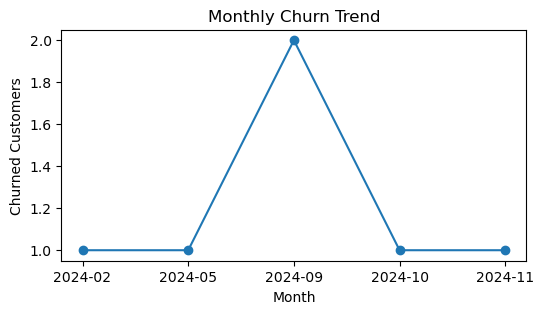

In [81]:
# 1. Convert the cancellation date into datetime format
df_visual["cancellation_date"] = pd.to_datetime(
    df_visual["cancellation_date"], errors="coerce"
)

# 2. Extract the year and month as a monthly period
df_visual["cancellation_month"] = (
    df_visual["cancellation_date"].dt.to_period("M")
)

# 3. Select churned customers and count records per month
churn_trend = (
    df_visual[df_visual["churn_flag"] == 1]
    .groupby("cancellation_month")
    .size()
)

# 4. Create the chart canvas, draw the line, and add details
plt.figure(figsize=(6, 3))

plt.plot(
    churn_trend.index.astype(str),
    churn_trend.values,
    marker="o")

plt.title("Monthly Churn Trend")
plt.xlabel("Month")
plt.ylabel("Churned Customers")
plt.show()


* **`pd.to_datetime()`** converts the text dates into actual datetime formats that Python understands.
* **`.dt.to_period("M")`** extracts the year and month so you can group data by month (e.g., "2026-10").
* **`df_visual["churn_flag"] == 1`** filters the dataset to select only the customers who actually cancelled.
* **`groupby("cancellation_month").size()`** groups the filtered data by month and counts how many customers left in each period.
* **`plt.figure(figsize=(6, 3))`** sets up the size and dimensions of your chart window.
* **`plt.plot(..., marker="o")`** draws the trend line and places a clear dot marker on each month's data point.
* **`plt.title()`, `plt.xlabel()`, and `plt.ylabel()`** add labels to explain what the graph is showing.
* **`plt.show()`** renders and outputs the finished chart on your screen.


### 2. Churn Rate by Plan Type

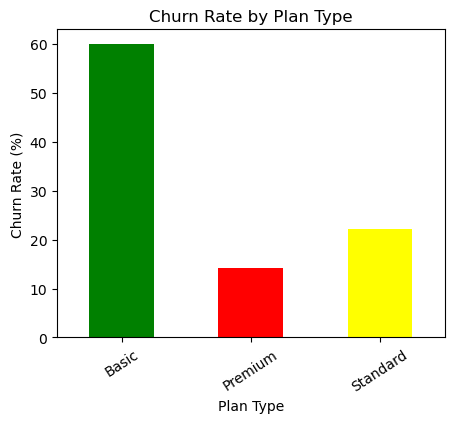

In [82]:
# Calculate churn percentage per plan type
churn_plan = df_visual.groupby("plan_type")["churn_flag"].mean() * 100

# Plot the results
plt.figure(figsize=(5,4))
churn_plan.plot(kind='bar', color=['green', 'red', 'yellow'])

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation = 33)
plt.show()

* **`groupby("plan_type")`** groups your customers by the specific subscription plan they are on.
* **`.mean()`** calculates the average churn rate for each of those plan groups.
* **`kind="bar"`** tells the plotting tool to display the final comparison as a vertical bar chart.
* **`plt.title()`, `plt.xlabel()`, and `plt.ylabel()`** add titles and axis text to clearly describe the comparison.

### 3. Churn by State

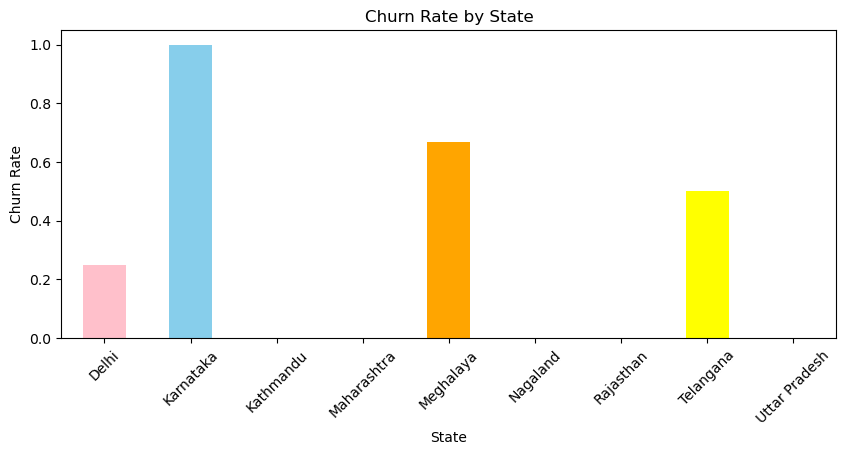

In [83]:
churn_state = df_visual.groupby('state')['churn_flag'].mean()

churn_state.plot(kind='bar', color = ['pink', 'skyblue', 'yellow', 'lightgreen', 'orange'] , figsize=(10, 4))

plt.title('Churn Rate by State')
plt.xlabel('State')
plt.ylabel('Churn Rate')
plt.xticks(rotation=45)
plt.show()

# Visulaization using Seaborn

#### 1. Heatmap — Correlation Matrix

In [84]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [85]:
df_visual[
    [
        "plan_type",
        "contract_type",
        "churn_score",
        "churn_flag",
        "churn_risk",
        "escalations"
    ]
].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0.0
1,Premium,Annual,91,1,high,0.0
2,Basic,Monthly,34,0,low,0.0
3,Premium,Annual,8,0,low,0.0
4,Standard,Monthly,88,1,high,0.0


#### 2. Convert text into numbers

In [86]:
df_encoded = df_visual[
    ['plan_type', 'contract_type', 'churn_score',
     'churn_flag', 'churn_risk', 'escalations']
].copy()

orders = {
    'plan_type': ['Basic', 'Standard', 'Premium'],
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
}
for col, order in orders.items():
    df_encoded[col] = pd.Categorical(
        df_encoded[col],
        categories=order,
        ordered=True
    ).codes

In [87]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0.0
1,Premium,Annual,91,1,high,0.0
2,Basic,Monthly,34,0,low,0.0
3,Premium,Annual,8,0,low,0.0
4,Standard,Monthly,88,1,high,0.0


In [88]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0.0
1,2,1,91,1,2,0.0
2,0,0,34,0,0,0.0
3,2,1,8,0,0,0.0
4,1,0,88,1,2,0.0


## Heatmap

<Axes: >

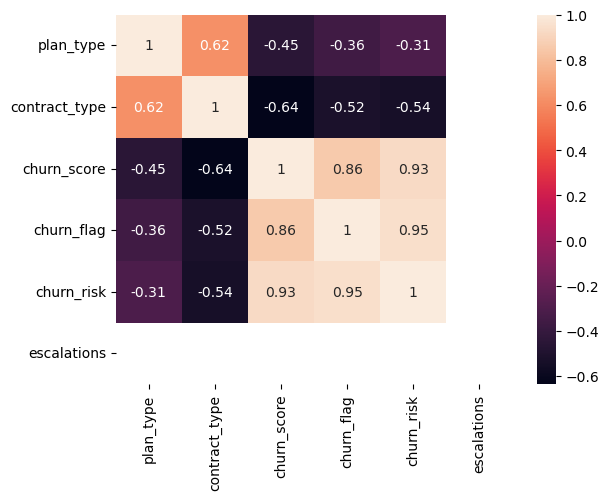

In [89]:
sns.heatmap(df_encoded.corr(), annot=True)


* **`.corr()`** calculates the pairwise correlation coefficients between all numeric columns to show how they relate to one another.
* **`sns.heatmap()`** displays these relationship scores visually as a color-coded grid.
* **`annot=True`** prints the actual numeric correlation values directly inside each grid cell for precise reading.


## Pairplot

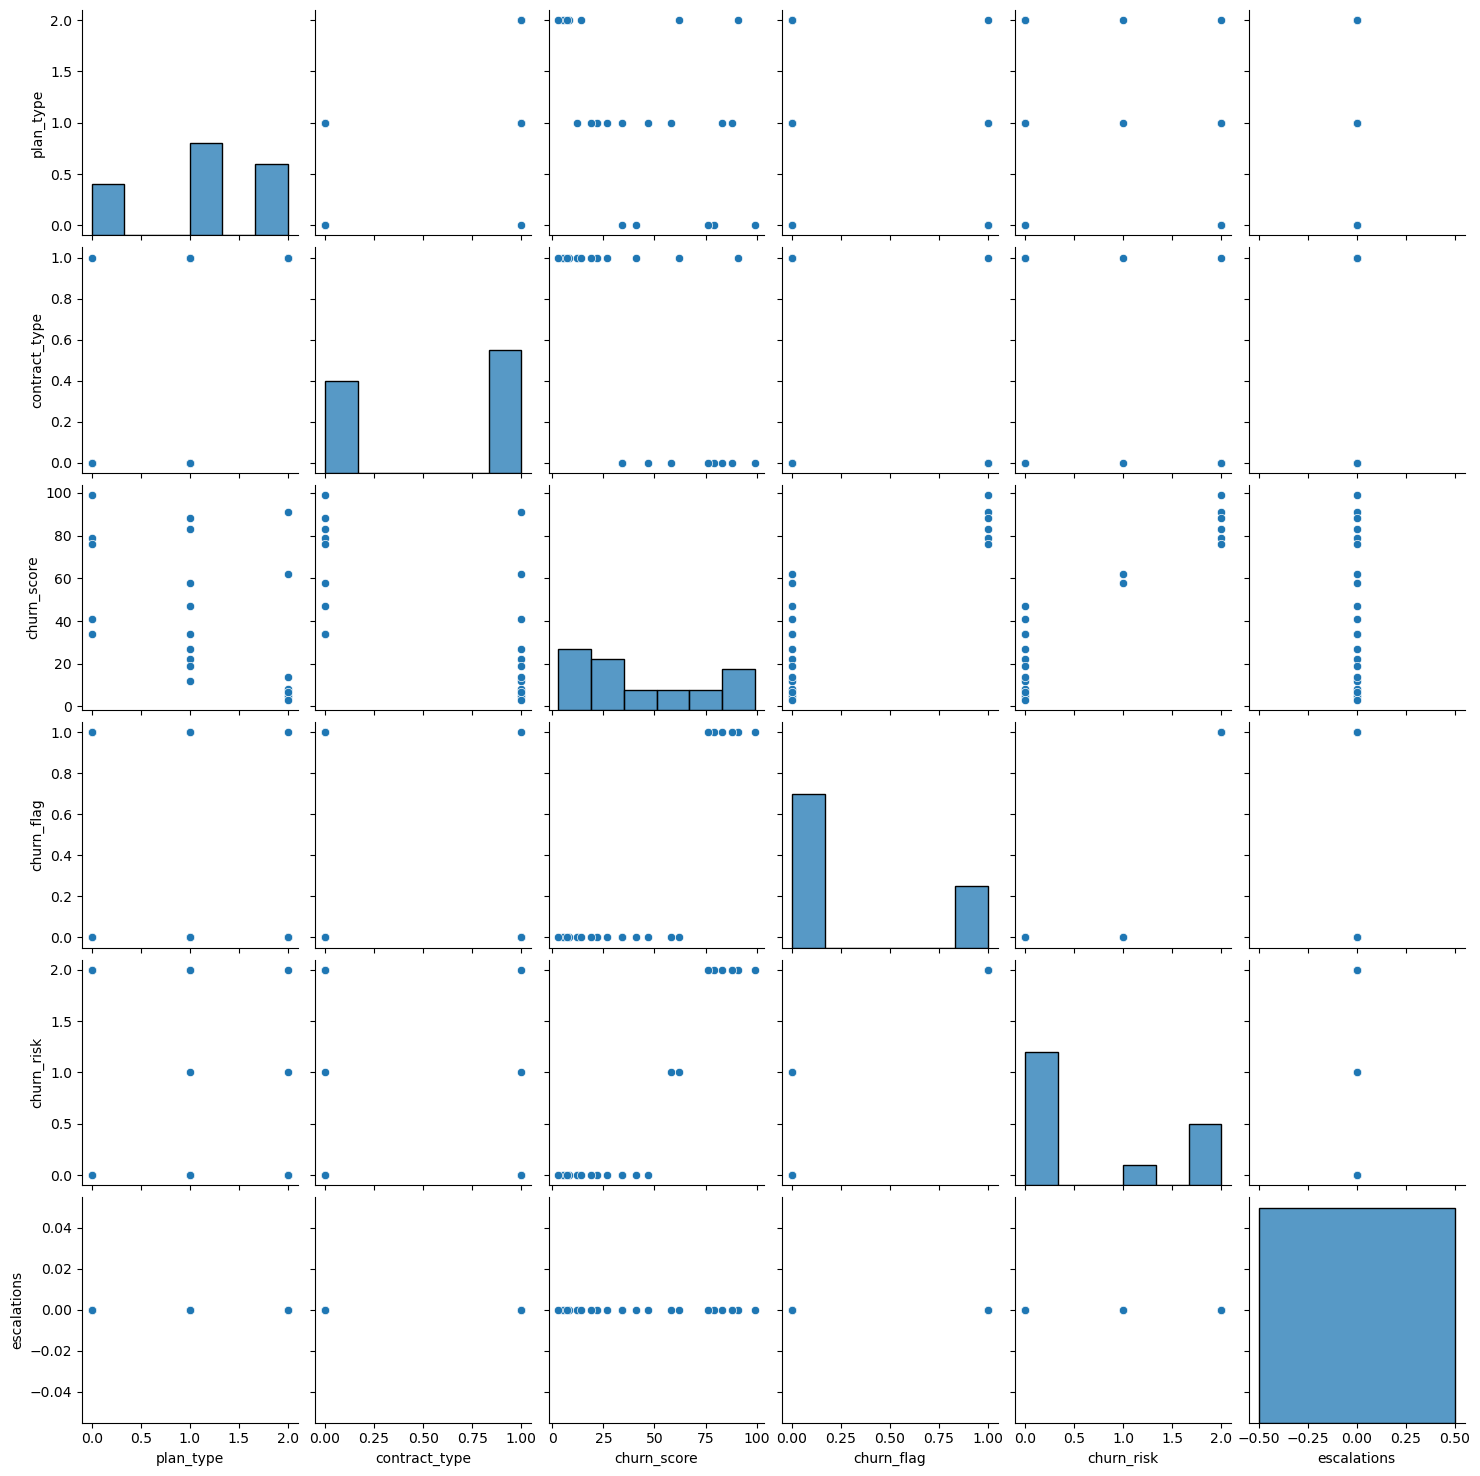

In [90]:
sns.pairplot(df_encoded)

## Categorical plot

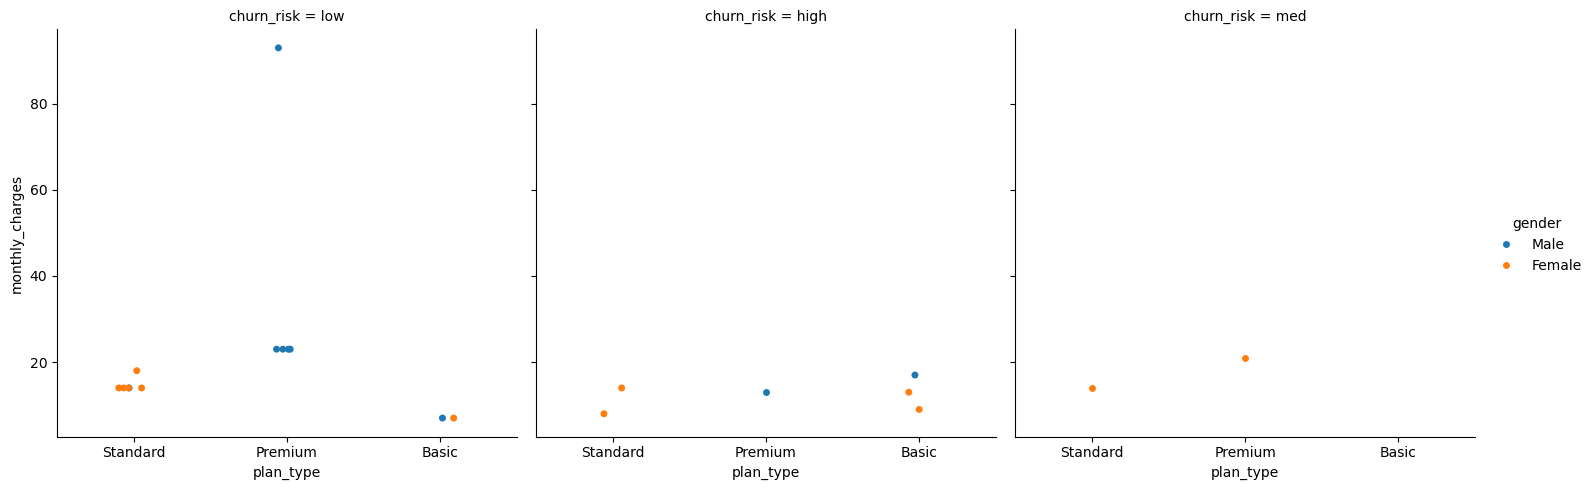

In [91]:
sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

# Pivot table

- A pivot table summarizes data by grouping it into categories and applying calculations such as sum, average or count.

In [92]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222



* **`df_visual`** is the main DataFrame containing all the customer data being analyzed.
* **`index="plan_type"`** sets the rows of your summary table to group results by each unique subscription plan.
* **`values="churn_flag"`** specifies the column you want to look at and summarize.
* **`aggfunc="mean"`** calculates the average churn rate for each plan group instead of just adding them up.


In [93]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91



| Column | Aggregation | Meaning |
| :--- | :--- | :--- |
| **`monthly_charges`** | `sum` | Total recorded monthly charges across the dataset |
| **`customerid`** | `nunique` | Count of unique or distinct customers (ignoring duplicate rows) |
| **`churn_flag`** | `mean` | The average churn rate (proportion of customers who left) |
